In [2]:
import pandas as pd
import numpy as np
import scipy.optimize as so
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

from ctREFPROP.ctREFPROP import REFPROPFunctionLibrary
import os

data = pd.read_excel('ODU#2_5min_v2_weekend_avg.xlsx')

In [3]:
data

,timestamp,IDU0_Operation_On&OFF,IDU0_Setting_temperature,IDU0_Current_Indoor_fan_wind,IDU0_Indoor_temperature,IDU0_Indoor_unit_ABS_Req_capacity,IDU0_Thermo_status,IDU1_Operation_On&OFF,IDU1_Setting_temperature,IDU1_Current_Indoor_fan_wind,...,Day_cos,Year_sin,Year_cos,Weekday,hour,minutes,TP_minus_LP,IAT_minus_OAT,ST_minus_IAT,ST_minus_OAT
0,2022-06-05 14:20:00,0.0,28.0,0.0,29.10,27.0,0.0,0.0,26.0,0.0,...,-0.819152,-0.573576,-0.819152,Sunday,14,20,7.600000,4.458278,NaN,NaN
1,2022-06-05 14:25:00,0.0,28.0,0.0,29.10,27.0,0.0,0.0,26.0,0.0,...,-0.806445,-0.591310,-0.806445,Sunday,14,25,7.600000,4.513476,NaN,NaN
2,2022-06-05 14:30:00,0.0,28.0,0.0,29.10,27.0,0.0,0.0,26.0,0.0,...,-0.793353,-0.608761,-0.793353,Sunday,14,30,7.600000,4.590012,NaN,NaN
3,2022-06-05 14:35:00,0.0,28.0,0.0,29.19,27.0,0.0,0.0,26.0,0.0,...,-0.779884,-0.625923,-0.779884,Sunday,14,35,7.536667,4.565265,NaN,NaN
4,2022-06-05 14:40:00,0.0,28.0,0.0,29.20,27.0,0.0,0.0,26.0,0.0,...,-0.766044,-0.642788,-0.766044,Sunday,14,40,7.413793,4.562081,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13392,2022-07-22 02:20:00,1.0,4.0,10.0,25.10,27.0,1.0,1.0,4.0,10.0,...,0.819152,0.573576,0.819152,Friday,2,20,2.600000,-0.885159,-20.314841,-21.2
13393,2022-07-22 02:25:00,1.0,4.0,10.0,25.10,27.0,1.0,1.0,4.0,10.0,...,0.806445,0.591310,0.806445,Friday,2,25,2.600000,-0.885159,-20.314841,-21.2
13394,2022-07-22 02:30:00,1.0,4.0,10.0,25.10,27.0,1.0,1.0,4.0,10.0,...,0.793353,0.608761,0.793353,Friday,2,30,2.600000,-0.885159,-20.314841,-21.2
13395,2022-07-22 02:35:00,1.0,4.0,10.0,25.10,27.0,1.0,1.0,4.0,10.0,...,0.779884,0.625923,0.779884,Friday,2,35,2.600000,-0.885159,-20.314841,-21.2


In [4]:
data.loc[:, 'inner_heat'] = 0


In [5]:
data.loc[(data["hour"] < 18) & (data["hour"] > 8) & (data["Weekday"] != 'Saturday') & (data["Weekday"] != 'Sunday'), 
         ["inner_heat"]] = 1

In [6]:
data.columns

Index(['timestamp', 'IDU0_Operation_On&OFF', 'IDU0_Setting_temperature',
       'IDU0_Current_Indoor_fan_wind', 'IDU0_Indoor_temperature',
       'IDU0_Indoor_unit_ABS_Req_capacity', 'IDU0_Thermo_status',
       'IDU1_Operation_On&OFF', 'IDU1_Setting_temperature',
       'IDU1_Current_Indoor_fan_wind', 'IDU1_Indoor_temperature',
       'IDU1_Indoor_unit_ABS_Req_capacity', 'IDU1_Thermo_status',
       'IDU2_Operation_On&OFF', 'IDU2_Setting_temperature',
       'IDU2_Current_Indoor_fan_wind', 'IDU2_Indoor_temperature',
       'IDU2_Indoor_unit_ABS_Req_capacity', 'IDU2_Thermo_status',
       'IDU3_Operation_On&OFF', 'IDU3_Setting_temperature',
       'IDU3_Current_Indoor_fan_wind', 'IDU3_Indoor_temperature',
       'IDU3_Humidity', 'IDU3_Indoor_unit_ABS_Req_capacity',
       'IDU3_Thermo_status', 'IDU4_Operation_On&OFF',
       'IDU4_Setting_temperature', 'IDU4_Current_Indoor_fan_wind',
       'IDU4_Indoor_temperature', 'IDU4_Indoor_unit_ABS_Req_capacity',
       'IDU4_Thermo_status', 'OD

In [7]:
data.loc[(data["ODU1_operation_mode"] == 0), 
         ["ODU1_target_pressure"]] = 0

In [8]:
data.columns

Index(['timestamp', 'IDU0_Operation_On&OFF', 'IDU0_Setting_temperature',
       'IDU0_Current_Indoor_fan_wind', 'IDU0_Indoor_temperature',
       'IDU0_Indoor_unit_ABS_Req_capacity', 'IDU0_Thermo_status',
       'IDU1_Operation_On&OFF', 'IDU1_Setting_temperature',
       'IDU1_Current_Indoor_fan_wind', 'IDU1_Indoor_temperature',
       'IDU1_Indoor_unit_ABS_Req_capacity', 'IDU1_Thermo_status',
       'IDU2_Operation_On&OFF', 'IDU2_Setting_temperature',
       'IDU2_Current_Indoor_fan_wind', 'IDU2_Indoor_temperature',
       'IDU2_Indoor_unit_ABS_Req_capacity', 'IDU2_Thermo_status',
       'IDU3_Operation_On&OFF', 'IDU3_Setting_temperature',
       'IDU3_Current_Indoor_fan_wind', 'IDU3_Indoor_temperature',
       'IDU3_Humidity', 'IDU3_Indoor_unit_ABS_Req_capacity',
       'IDU3_Thermo_status', 'IDU4_Operation_On&OFF',
       'IDU4_Setting_temperature', 'IDU4_Current_Indoor_fan_wind',
       'IDU4_Indoor_temperature', 'IDU4_Indoor_unit_ABS_Req_capacity',
       'IDU4_Thermo_status', 'OD

In [9]:
data.loc[6000, :]

timestamp                                      2022-06-26 10:20:00
IDU0_Operation_On&OFF                                          0.0
IDU0_Setting_temperature                                      28.0
IDU0_Current_Indoor_fan_wind                                   0.0
IDU0_Indoor_temperature                                       29.7
IDU0_Indoor_unit_ABS_Req_capacity                             27.0
IDU0_Thermo_status                                             0.0
IDU1_Operation_On&OFF                                          0.0
IDU1_Setting_temperature                                      24.0
IDU1_Current_Indoor_fan_wind                                   0.0
IDU1_Indoor_temperature                                      29.19
IDU1_Indoor_unit_ABS_Req_capacity                             34.0
IDU1_Thermo_status                                             0.0
IDU2_Operation_On&OFF                                          0.0
IDU2_Setting_temperature                                      

In [10]:
'IDU' + str(0) + '_Current_Indoor_fan_wind'

'IDU0_Current_Indoor_fan_wind'

In [11]:
# sum_idu = 0
# for i in range(0,5):
#     sum_idu = sum_idu + data.loc[6000, 'IDU' + str(i) + '_Current_Indoor_fan_wind'] * data.loc[6000, 'IDU' + str(i) + '_Indoor_unit_ABS_Req_capacity']

# op_rate = sum_idu / (0.8*250*10)

In [13]:
#op_rate

In [14]:
data.loc[1000, 'IDU0_Current_Indoor_fan_wind']

0.0

In [15]:
data.loc[:, 'op_rate'] = 0

In [16]:
data["op_rate"] = ( data['IDU0_Current_Indoor_fan_wind'] * data['IDU0_Indoor_unit_ABS_Req_capacity'] 
                         + data['IDU1_Current_Indoor_fan_wind'] * data['IDU1_Indoor_unit_ABS_Req_capacity'] 
                         + data['IDU2_Current_Indoor_fan_wind'] * data['IDU2_Indoor_unit_ABS_Req_capacity']  
                         + data['IDU3_Current_Indoor_fan_wind'] * data['IDU3_Indoor_unit_ABS_Req_capacity']
                         + data['IDU4_Current_Indoor_fan_wind'] * data['IDU4_Indoor_unit_ABS_Req_capacity'] ) / (1.0*250*10) #10HP

In [17]:
# Period 1

train_data = data[data['timestamp'].between('2022-07-01 05:00:00','2022-07-22 23:59:00')] #7/11
#train_data = data[data['timestamp'].between('2022-06-06 23:45:00','2022-07-20 23:59:00')]
#별도 환기를 안 한다고 보장할 수 있는가?
train_data_1 = data[data['timestamp'].between('2022-07-01 22:00:00','2022-07-04 07:00:00')]

In [18]:
train_data.head()

,timestamp,IDU0_Operation_On&OFF,IDU0_Setting_temperature,IDU0_Current_Indoor_fan_wind,IDU0_Indoor_temperature,IDU0_Indoor_unit_ABS_Req_capacity,IDU0_Thermo_status,IDU1_Operation_On&OFF,IDU1_Setting_temperature,IDU1_Current_Indoor_fan_wind,...,Year_cos,Weekday,hour,minutes,TP_minus_LP,IAT_minus_OAT,ST_minus_IAT,ST_minus_OAT,inner_heat,op_rate
7376,2022-07-01 05:00:00,0.0,28.0,0.0,27.7,27.0,0.0,0.0,24.0,0.0,...,0.258819,Friday,5,0,6.7,5.238869,NaN,NaN,0,0.0
7377,2022-07-01 05:05:00,0.0,28.0,0.0,27.7,27.0,0.0,0.0,24.0,0.0,...,0.237686,Friday,5,5,6.7,5.238869,NaN,NaN,0,0.0
7378,2022-07-01 05:10:00,0.0,28.0,0.0,27.7,27.0,0.0,0.0,24.0,0.0,...,0.216440,Friday,5,10,6.7,5.238869,NaN,NaN,0,0.0
7379,2022-07-01 05:15:00,0.0,28.0,0.0,27.7,27.0,0.0,0.0,24.0,0.0,...,0.195090,Friday,5,15,6.7,5.238869,NaN,NaN,0,0.0
7380,2022-07-01 05:20:00,0.0,28.0,0.0,27.7,27.0,0.0,0.0,24.0,0.0,...,0.173648,Friday,5,20,6.7,5.238869,NaN,NaN,0,0.0


In [19]:
# df = pd.DataFrame(train_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT', 'inner_heat']].values,
#                            columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int', 'inner_heat'])
df = pd.DataFrame(train_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_Low_pressure_(1_second_value)', 'op_rate', 'IAT', 'inner_heat']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int', 'inner_heat'])
df['Time'] = 300 * df.index
df.loc[df['OP_mode'] == 0, 'P_targ'] = 0

# df_1 = pd.DataFrame(train_data_1[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT', 'inner_heat']].values,
#                            columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int', 'inner_heat'])
df_1 = pd.DataFrame(train_data_1[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'op_rate', 'IAT', 'inner_heat']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int', 'inner_heat'])
df_1['Time'] = 300 * df_1.index
df_1.loc[df['OP_mode'] == 0, 'P_targ'] = 0

In [20]:
df.head()

,T_ext,P_targ,OP_mode,T_int,inner_heat,Time
0,22.5,0.0,0.0,27.738869,0.0,0
1,22.5,0.0,0.0,27.738869,0.0,300
2,22.5,0.0,0.0,27.738869,0.0,600
3,22.5,0.0,0.0,27.738869,0.0,900
4,22.5,0.0,0.0,27.738869,0.0,1200


In [21]:
inputs = df[['Time', 'T_ext', 'P_targ', 'OP_mode', 'inner_heat']].values
output = df['T_int'].values

In [22]:
inputs_1 = df_1[['Time', 'T_ext']].values
output_1 = df_1['T_int'].values

In [23]:
df.loc[2500, :]

T_ext             28.300000
P_targ             0.000000
OP_mode            0.000000
T_int             29.746643
inner_heat         0.000000
Time          750000.000000
Name: 2500, dtype: float64

In [24]:
#df_1.to_csv('temp.csv')
#df.to_csv('temp.csv')

In [25]:
#output_1

In [26]:
# 휴일 데이타만 이용해서 만들어야 한다

# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, te_0): #(inputs, Ri, Ro, Ci, Ce, te_0):

    time = inputs_1[:, 0]
    to   = inputs_1[:, 1]
    # phi_tp = inputs[:, 2]
    # phi_ac = inputs[:, 3]
    # inner_heat = inputs[:, 4]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output_1[0]
    te[0] = te_0 #te_0 #31.7 #( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)
    
    #Ce = Ci*10

    # Loop for calculating all temperatures
    for t in range(1, len(output_1)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri) # + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] + Aih*inner_heat[t-1])
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro ) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs_1,
                            ydata=output_1,
                            #p0=(0.1, 0.2, 850, 6e4, 30), #, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            bounds=([0.01, 0.01, 1000, 2e4, 20], [1, 5, 2000, 2.5e5, 45]),
                            maxfev=10000)

                            # p0=(0.1, 0.2, 850, 6e4, 30), #, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            # bounds=([0.01, 0.01, 800,5e4,25], [1, 20, 8000, 5e5,45]),
                            # p0=(1e1, 1e2, 1e4, 1e4, 30), #, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            # bounds=([0,0,1e4,1e4,25], [1e3, 1e5, 1e6, 1e6,45]),
                            # p0=(1e1, 1e2, 1e3, 1e4, 31), #, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2,  1e7, 1e1, -1e1, 1e1), 
                            # bounds=([1e1,1e2,1e3,1e4,25], [1e4, 1e5, 1e6, 1e6, 45]),

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'te_0']) # 'te_0'
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output_1 , simpleRC(inputs_1, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4]))) #, p_opt[4], p_opt[5],  p_opt[6])))

                avg           std
Ri         0.172560  8.554866e+03
Ro         1.798633  5.872331e+04
Ci      1157.592162  5.806908e+07
Ce    100446.997227  3.319394e+09
te_0      29.520155  4.936126e+02

r^2: 0.3556089064442237


In [27]:
res1.loc['Ri', 'avg']

0.1725598937511885

In [28]:
Ri   = res1.loc['Ri', 'avg']
Ro  =  res1.loc['Ro', 'avg']
Ci  =  res1.loc['Ci', 'avg']
Ce  = res1.loc['Ce', 'avg']

In [29]:
inputs[:, 2]

array([ 0. ,  0. ,  0. , ..., 10.6, 10.6, 10.6])

In [30]:
inputs[:, 3]

array([0.   , 0.   , 0.   , ..., 1.132, 1.132, 1.132])

In [31]:
root = 'C:/Refprop_dll' # Change this path as needed
RP = REFPROPFunctionLibrary(root)
RP.SETPATHdll(root)

MKS = RP.GETENUMdll(0, "MKS").iEnum

fluid = 'R410A.MIX'
FLDpath1 = os.path.join(root,"mixtures",fluid)
sm = RP.SETMIXdll(fluid,'HMX.BNC','IIR') # in case of mixture, this sentence should be defined
RP.SETREFdll('IIR',2,sm.z,0,0,0,0)
z = sm.z  



In [33]:
print('\nr^2:',r2_score(output , simpleRC(inputs, -0.10, 3.54,   28.4 )))


r^2: -0.8163167607112696


In [36]:
# 운전율 개념으로 보수한다
# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Atp, Aac, Across, Aih, te_0, C_0, C_1):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3] #운전율
    inner_heat = inputs[:, 4]
    #print(Ri)
    
    # Ri   =     96.890123 
    # Ro  =  99945.405564 
    # Ci  =    643.912655 
    # Ce  = 636802.391929 

    # Ri        =29.914450ㅁ
    # Ro     =85466.425164
    # Ci      =2098.945674
    # Ce    =282548.400453
    #te_0      =30.698664

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = te_0 #( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
        dt = time[t] - time[t-1]
        if phi_ac[t-1] == 0 :
            ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Aih*inner_heat[t-1] + C_1 )
            # 외부에 드나드는 열량이 있다고 보는 것이 타당하지 않겠는가?
            # 에어컨을 켜지 않았다면 환기를 시도했을 가능성도 있다
        else:
            ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*(phi_tp[t-1]) + Aac*phi_ac[t-1] + Across*(phi_tp[t-1])*phi_ac[t-1] + Aih*inner_heat[t-1] + C_0 )
        #ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*(phi_tp[t-1]-C_sp) + Aac*phi_ac[t-1] + Aih*inner_heat[t-1] + C_0 )
        te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro ) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            #p0=(1e2, -1e2, 1e2, 25), #, 1e7, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            #bounds=([0, -1e2, 0, 20], [1e2, 0, 1e2, 40]),
                            bounds=([0, -35, -28, 0, 15, -5, -5], [5, -3, 28, 10, 40, 5, 5]),
                            maxfev=10000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Atp', 'Aac', 'Across', 'Aih', 'te_0', 'C_0', 'C_1'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5], p_opt[6])))

                 avg       std
Atp     8.769830e-02  0.254385
Aac    -3.500000e+01  3.745501
Across  2.642250e+00  0.393561
Aih     2.232786e-10  0.457866
te_0    2.636061e+01  0.117396
C_0     2.227854e+00  2.211795
C_1     2.023524e+00  0.046102

r^2: 0.24358631724533986


In [301]:
# 운전율 개념으로 보수한다
# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Atp, Aac, Aih, te_0, C_0, C_1, C_sp):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3] #운전율
    inner_heat = inputs[:, 4]
    #print(Ri)
    
    # Ri   =     96.890123 
    # Ro  =  99945.405564 
    # Ci  =    643.912655 
    # Ce  = 636802.391929 

    # Ri        =29.914450ㅁ
    # Ro     =85466.425164
    # Ci      =2098.945674
    # Ce    =282548.400453
    #te_0      =30.698664

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = te_0 #( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
        dt = time[t] - time[t-1]
        if phi_ac[t-1] < 0.1 :
            ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Aih*inner_heat[t-1] + C_1 )
        else:
            ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*(phi_tp[t-1]-C_sp) + Aac*phi_ac[t-1] + Aih*inner_heat[t-1] + C_0 )
        #ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*(phi_tp[t-1]-C_sp) + Aac*phi_ac[t-1] + Aih*inner_heat[t-1] + C_0 )
        te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro ) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            #p0=(1e2, -1e2, 1e2, 25), #, 1e7, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            #bounds=([0, -1e2, 0, 20], [1e2, 0, 1e2, 40]),
                            bounds=([0, -28, 0, 15, -5, -5, 5], [5, -3, 10, 40, 5, 5, 10]),
                            maxfev=10000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Atp', 'Aac', 'Aih', 'te_0', 'C_0', 'C_1','C_sp'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5], p_opt[6])))

            avg           std
Atp    1.749588      0.136843
Aac  -10.499002      0.827831
Aih    0.313379      0.399790
te_0  26.215895      0.144836
C_0    2.625493  52771.093677
C_1    2.240655      0.034955
C_sp   8.687828  30162.059157

r^2: 0.27103135982183835


In [75]:

# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Atp, Aac, Aih, te_0):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]
    inner_heat = inputs[:, 4]
    #print(Ri)
    
    # Ri   =     96.890123 
    # Ro  =  99945.405564 
    # Ci  =    643.912655 
    # Ce  = 636802.391929 

    # Ri        =29.914450ㅁ
    # Ro     =85466.425164
    # Ci      =2098.945674
    # Ce    =282548.400453
    #te_0      =30.698664

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = te_0 #( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] + Aih*inner_heat[t-1])
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro ) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            #p0=(1e2, -1e2, 1e2, 25), #, 1e7, 1e1, -1e1, 1e1), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            #bounds=([0, -1e2, 0, 20], [1e2, 0, 1e2, 40]),
                            bounds=([-10, -28, 0, 15], [10, 0, 10, 40]),
                            maxfev=10000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Atp', 'Aac', 'Aih', 'te_0'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3])))

               avg       std
Atp   7.344971e-02  0.243587
Aac  -2.937261e-01  2.534766
Aih   2.728885e-23  0.984595
te_0  2.703419e+01  0.258535

r^2: -0.2698151024822839


In [76]:





# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, Atp, Aac, Aih, te_0):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]
    inner_heat = inputs[:, 4]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = te_0 #( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] + Aih*inner_heat[t-1])
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro ) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            p0=(1e1, 1e1, 1e4, 1e4, 1e1, -1e1, 1e1, 25), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            bounds=([0, 0, 1e3, 0, 0, -1e5, 0, 15], [1e5, 1e5, 1e6, 1e6, 1e5, 0, 1e5, 40]),
                            maxfev=10000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'Atp', 'Aac', 'Aih', 'te_0'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5],  p_opt[6],  p_opt[7])))

                avg           std
Ri         0.227811  6.491476e+03
Ro      1783.310902  5.078076e+07
Ci    140979.451600  4.016726e+09
Ce     26948.473006  7.679194e+08
Atp        0.455819  1.298665e+04
Aac       -5.677999  1.617729e+05
Aih        0.000026  4.953081e+00
te_0      15.102267  4.043556e+02

r^2: 0.006753774310062743


In [304]:





# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, Atp, Aac, Aih, te_0):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]
    inner_heat = inputs[:, 4]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = te_0 #( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] + Aih*inner_heat[t-1])
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro ) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            p0=(1e1, 1e1, 1e3, 1e4, 1e1, -1e1, 1e1, 25), #p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1, 1e1), 
                            bounds=([0, 0, 1e2, 0, 0, -1e5, 0, 15], [1e5, 1e6, 1e6, 1e6, 1e5, 0, 1e5, 40]),
                            maxfev=10000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'Atp', 'Aac', 'Aih', 'te_0'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5],  p_opt[6],  p_opt[7])))

               avg           std
Ri    2.318045e+01  4.509078e+00
Ro    1.000000e+06  7.687577e-08
Ci    1.000000e+02  1.930743e+01
Ce    1.000000e+06  2.034747e-03
Atp   4.937587e-02  9.576052e-03
Aac  -6.024681e-01  1.156620e-01
Aih   6.383898e-20  1.701141e-03
te_0  2.887753e+01  1.674191e-02

r^2: 0.7345860138687581


In [ ]:
df.head(10)

In [ ]:
res1

In [189]:
df = df.set_index('Time')

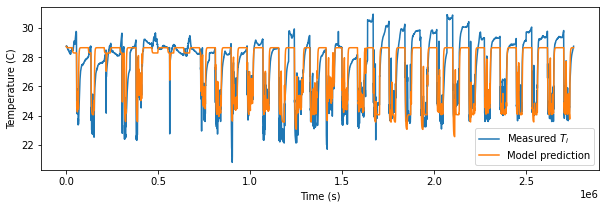

In [190]:
plt.figure(figsize=(10,3))
plt.plot(df.index, output, label='Measured $T_i$')
plt.plot(df.index, simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5],  p_opt[6]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

In [191]:
def simpleRC_1(inputs, Ri, Ro, Ci, Ce, Atp, Aac, Aih):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]
    inner_heat = inputs[:, 4]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = ( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] + Aih*inner_heat[t-1])
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro) #te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
    
    return te
    
    return te

In [192]:
inputs

array([[0.00000000e+00, 1.76000000e+01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [3.00000000e+02, 1.76000000e+01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [6.00000000e+02, 1.76000000e+01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       ...,
       [2.75910000e+06, 2.47000000e+01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [2.75940000e+06, 2.46833333e+01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [2.75970000e+06, 2.46000000e+01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00]])

In [193]:
output

array([28.73100304, 28.76039618, 28.77829787, ..., 28.69319149,
       28.72239716, 28.7451504 ])

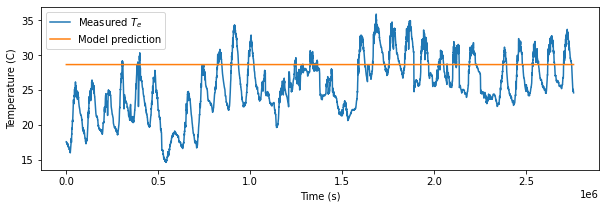

In [194]:
plt.figure(figsize=(10,3))
plt.plot(df.index, df['T_ext'].values, label='Measured $T_e$')
plt.plot(df.index, simpleRC_1(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5],  p_opt[6]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

In [29]:
simpleRC_1(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5])

array([28.60603615, 28.60603615, 28.60603615, ..., 28.60602851,
       28.60602851, 28.60602851])

In [28]:
inputs

array([[0.00000000e+00, 1.76000000e+01, 0.00000000e+00, 0.00000000e+00],
       [3.00000000e+02, 1.76000000e+01, 0.00000000e+00, 0.00000000e+00],
       [6.00000000e+02, 1.76000000e+01, 0.00000000e+00, 0.00000000e+00],
       ...,
       [2.75910000e+06, 2.47000000e+01, 0.00000000e+00, 0.00000000e+00],
       [2.75940000e+06, 2.46833333e+01, 0.00000000e+00, 0.00000000e+00],
       [2.75970000e+06, 2.46000000e+01, 0.00000000e+00, 0.00000000e+00]])

In [30]:
p_opt

array([ 3.52603209e+00,  3.10543339e+02,  5.17463361e+02,  2.65477567e+11,
        3.10768661e-01, -3.78170148e+00])

In [23]:
df

,T_ext,P_targ,OP_mode,T_int
Time,,,,
0,17.600000,0.0,0.0,28.731003
300,17.600000,0.0,0.0,28.760396
600,17.600000,0.0,0.0,28.778298
900,17.503333,0.0,0.0,28.778298
1200,17.500000,0.0,0.0,28.778298
...,...,...,...,...
2758500,24.800000,0.0,0.0,28.677051
2758800,24.716667,0.0,0.0,28.693191
2759100,24.700000,0.0,0.0,28.693191


In [5]:
p_opt_1P = p_opt

In [31]:
# Period 2

train_data = data[data['timestamp'].between('2022-06-21','2022-07-04 23:59:00')]

df = pd.DataFrame(train_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int'])
df['Time'] = 300 * df.index
df.loc[df['OP_mode'] == 0, 'P_targ'] = 0


inputs = df[['Time', 'T_ext', 'P_targ', 'OP_mode']].values
output = df['T_int'].values

# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, Atp, Aac):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = ( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )

    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1), 
                            maxfev=5000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'Atp', 'Aac'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5])))

              avg           std
Ri   2.175279e-02  1.127529e+02
Ro   8.568740e-01  4.433354e+03
Ci   8.685441e+04  4.487089e+08
Ce  -6.864545e+08  3.540507e+12
Atp  7.414522e+01  3.830595e+05
Aac -8.086085e+02  4.177540e+06

r^2: 0.7817721842508276


In [32]:
df = df.set_index('Time')

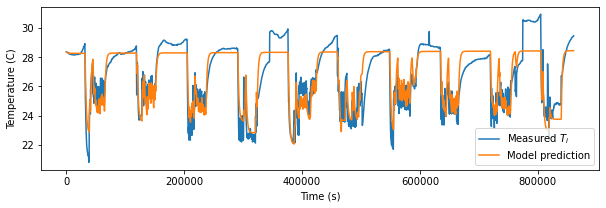

In [33]:
plt.figure(figsize=(10,3))
plt.plot(df.index, output, label='Measured $T_i$')
plt.plot(df.index, simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

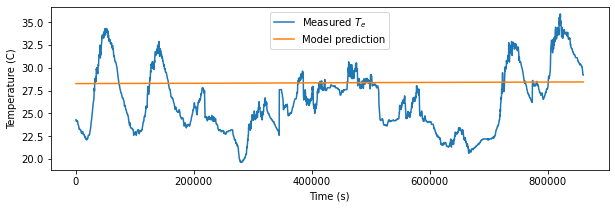

In [34]:
plt.figure(figsize=(10,3))
plt.plot(df.index, df['T_ext'].values, label='Measured $T_e$')
plt.plot(df.index, simpleRC_1(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

In [35]:
te_list = simpleRC_1(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5])

In [36]:
te_list

array([28.26089371, 28.26089371, 28.26089408, ..., 28.44257611,
       28.44257568, 28.44257529])

In [9]:
p_opt_2P = p_opt

In [11]:
# Period 3

train_data = data[data['timestamp'].between('2022-06-22','2022-07-05 23:59:00')]

df = pd.DataFrame(train_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int'])
df['Time'] = 300 * df.index
df.loc[df['OP_mode'] == 0, 'P_targ'] = 0


inputs = df[['Time', 'T_ext', 'P_targ', 'OP_mode']].values
output = df['T_int'].values

# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, Atp, Aac):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = ( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )

    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1), 
                            maxfev=5000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'Atp', 'Aac'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5])))

              avg           std
Ri   6.172962e-04  3.480965e+00
Ro   1.895307e+01  1.014517e+05
Ci   3.931770e+06  2.210103e+10
Ce  -7.043059e+09  3.959064e+13
Atp  2.080681e+03  1.169600e+07
Aac -2.444754e+04  1.374253e+08

r^2: 0.7831966457009745


In [12]:
df = df.set_index('Time')

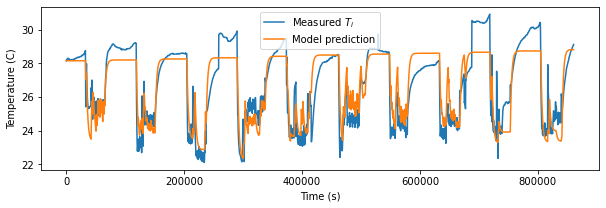

In [13]:
plt.figure(figsize=(10,3))
plt.plot(df.index, output, label='Measured $T_i$')
plt.plot(df.index, simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

In [14]:
p_opt_3P = p_opt

In [15]:
# Period 4

train_data = data[data['timestamp'].between('2022-06-23','2022-07-06 23:59:00')]

df = pd.DataFrame(train_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int'])
df['Time'] = 300 * df.index
df.loc[df['OP_mode'] == 0, 'P_targ'] = 0


inputs = df[['Time', 'T_ext', 'P_targ', 'OP_mode']].values
output = df['T_int'].values

# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, Atp, Aac):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = ( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )

    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1), 
                            maxfev=5000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'Atp', 'Aac'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5])))

              avg           std
Ri   7.706553e-02  5.387886e+02
Ro   2.125136e-01  1.485741e+03
Ci   2.903829e+04  2.036466e+08
Ce  -3.792266e+07  2.659869e+11
Atp  1.594078e+01  1.118058e+05
Aac -1.905197e+02  1.336271e+06

r^2: 0.7942897716414541


In [16]:
df = df.set_index('Time')

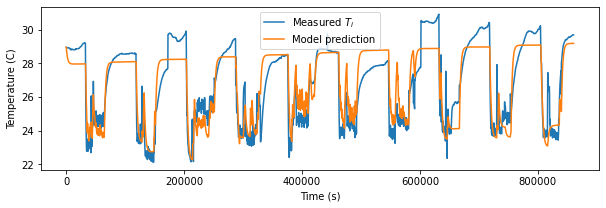

In [17]:
plt.figure(figsize=(10,3))
plt.plot(df.index, output, label='Measured $T_i$')
plt.plot(df.index, simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

In [18]:
p_opt_4P = p_opt

In [19]:
# Period 5

train_data = data[data['timestamp'].between('2022-06-24','2022-07-07 23:59:00')]

df = pd.DataFrame(train_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int'])
df['Time'] = 300 * df.index
df.loc[df['OP_mode'] == 0, 'P_targ'] = 0


inputs = df[['Time', 'T_ext', 'P_targ', 'OP_mode']].values
output = df['T_int'].values

# Function that will calculate the indoor temperature for a given value of R and C
def simpleRC(inputs, Ri, Ro, Ci, Ce, Atp, Aac):

    time = inputs[:, 0]
    to   = inputs[:, 1]
    phi_tp = inputs[:, 2]
    phi_ac = inputs[:, 3]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = output[0]
    te[0] = ( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )

    return ti


p_opt, p_cov = so.curve_fit(f=simpleRC,
                            xdata=inputs,
                            ydata=output,
                            p0=(1e-1, 1e-2, 1e4, 1e7, 1e1, -1e1), 
                            maxfev=5000)

# Saving results into a dataframe and displaying it
res1 = pd.DataFrame(index=['Ri', 'Ro', 'Ci', 'Ce', 'Atp', 'Aac'])
res1['avg'] = p_opt
res1['std'] = np.diag(p_cov)**0.5
print(res1)

print('\nr^2:',r2_score(output , simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5])))

<ipython-input-19-db44192c0225>:32: RuntimeWarning: overflow encountered in double_scalars
  ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
<ipython-input-19-db44192c0225>:33: RuntimeWarning: overflow encountered in double_scalars
  te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
<ipython-input-19-db44192c0225>:32: RuntimeWarning: invalid value encountered in double_scalars
  ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
<ipython-input-19-db44192c0225>:33: RuntimeWarning: invalid value encountered in double_scalars
  te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )


              avg           std
Ri   3.055459e-02  2.830525e+02
Ro   3.139709e-01  2.908468e+03
Ci   7.807056e+04  7.258845e+08
Ce  -7.578285e+07  7.046976e+11
Atp  3.902124e+01  3.628494e+05
Aac -4.720912e+02  4.389882e+06

r^2: 0.8029727076877596


In [20]:
df = df.set_index('Time')

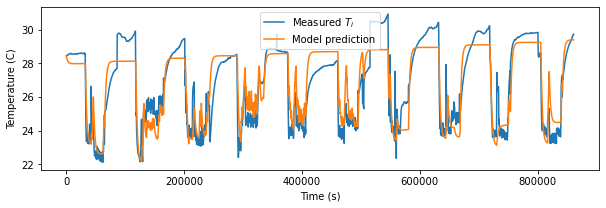

In [21]:
plt.figure(figsize=(10,3))
plt.plot(df.index, output, label='Measured $T_i$')
plt.plot(df.index, simpleRC(inputs, p_opt[0], p_opt[1], p_opt[2], p_opt[3], p_opt[4], p_opt[5]), label='Model prediction')
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

In [22]:
p_opt_5P = p_opt

### Prediction

In [23]:
pred_data = data[data['timestamp'].between('2022-07-08','2022-07-08 23:59:00')]

In [24]:
pred_df = pd.DataFrame(pred_data[['ODU1_Outdoor_temperature_(1_second_average)', 'ODU1_target_pressure', 'ODU1_operation_mode', 'IAT']].values,
                           columns = ['T_ext', 'P_targ', 'OP_mode', 'T_int'])
pred_df['Time'] = 300 * pred_df.index

pred_df.loc[pred_df['OP_mode'] == 0, 'P_targ'] = 0

In [25]:
pred_inputs = pred_df[['Time', 'T_ext', 'P_targ', 'OP_mode']].values
pred_output = pred_df['T_int'].values

In [26]:
def pred_simpleRC(pred_inputs, Ri, Ro, Ci, Ce, Atp, Aac):

    time = pred_inputs[:, 0]
    to   = pred_inputs[:, 1]
    phi_tp = pred_inputs[:, 2]
    phi_ac = pred_inputs[:, 3]

    ti = np.zeros(len(time))
    te = np.zeros(len(time))

    # Initial temperatures
    ti[0] = pred_output[0]
    te[0] = ( Ri*to[0] + Ro*ti[0] ) / (Ri + Ro)

    # Loop for calculating all temperatures
    for t in range(1, len(pred_output)):
      dt = time[t] - time[t-1]
      ti[t] = ti[t-1] + dt / Ci * ( (te[t-1]-ti[t-1])/Ri + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )
      te[t] = te[t-1] + dt / Ce * ( (ti[t-1]-te[t-1])/Ri + (to[t-1]-te[t-1])/Ro + Atp*phi_tp[t-1] + Aac*phi_ac[t-1] )

    return ti

In [27]:
pred_outputs_avg = (pred_simpleRC(pred_inputs, p_opt_1P[0], p_opt_1P[1], p_opt_1P[2], p_opt_1P[3], p_opt_1P[4], p_opt_1P[5]) 
+ pred_simpleRC(pred_inputs, p_opt_2P[0], p_opt_2P[1], p_opt_2P[2], p_opt_2P[3], p_opt_2P[4], p_opt_2P[5])
+ pred_simpleRC(pred_inputs, p_opt_3P[0], p_opt_3P[1], p_opt_3P[2], p_opt_3P[3], p_opt_3P[4], p_opt_3P[5])
+ pred_simpleRC(pred_inputs, p_opt_4P[0], p_opt_4P[1], p_opt_4P[2], p_opt_4P[3], p_opt_4P[4], p_opt_4P[5])
+ pred_simpleRC(pred_inputs, p_opt_5P[0], p_opt_5P[1], p_opt_5P[2], p_opt_5P[3], p_opt_5P[4], p_opt_5P[5])) / 5

In [28]:
print('1P r^2:',r2_score(pred_output , pred_simpleRC(pred_inputs, p_opt_1P[0], p_opt_1P[1], p_opt_1P[2], p_opt_1P[3], p_opt_1P[4], p_opt_1P[5])))
print('2P r^2:',r2_score(pred_output , pred_simpleRC(pred_inputs, p_opt_2P[0], p_opt_2P[1], p_opt_2P[2], p_opt_2P[3], p_opt_2P[4], p_opt_2P[5])))
print('3P r^2:',r2_score(pred_output , pred_simpleRC(pred_inputs, p_opt_3P[0], p_opt_3P[1], p_opt_3P[2], p_opt_3P[3], p_opt_3P[4], p_opt_3P[5])))
print('4P r^2:',r2_score(pred_output , pred_simpleRC(pred_inputs, p_opt_4P[0], p_opt_4P[1], p_opt_4P[2], p_opt_4P[3], p_opt_4P[4], p_opt_4P[5])))
print('5P r^2:',r2_score(pred_output , pred_simpleRC(pred_inputs, p_opt_5P[0], p_opt_5P[1], p_opt_5P[2], p_opt_5P[3], p_opt_5P[4], p_opt_5P[5])))

print('\nAvg r^2:',r2_score(pred_output , pred_outputs_avg))

1P r^2: 0.6701673552873215
2P r^2: 0.677714563699501
3P r^2: 0.6445768630087201
4P r^2: 0.808705407611801
5P r^2: 0.7129304007062298

Avg r^2: 0.7128640570910088


In [29]:
pred_df = pred_df.set_index('Time')

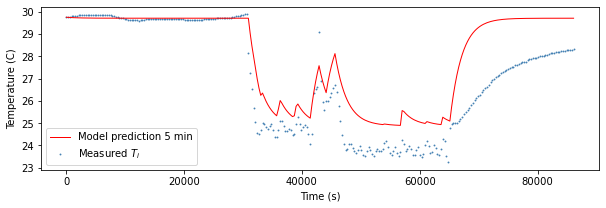

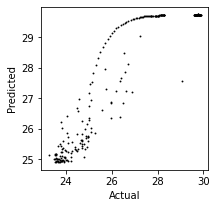

In [30]:
# Forecast graph
plt.figure(figsize=(10,3))
plt.scatter(pred_df.index, pred_output, color="steelblue", marker='.', label='Measured $T_i$', s=3)
plt.plot(pred_df.index, pred_simpleRC(pred_inputs, p_opt_1P[0], p_opt_1P[1], p_opt_1P[2], p_opt_1P[3], p_opt_1P[4], p_opt_1P[5]), 
         color="red",linewidth=1, label='Model prediction 5 min')

plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

# Scatter plots
plt.figure(figsize=(3,3))
plt.scatter(pred_output, pred_simpleRC(pred_inputs, p_opt_1P[0], p_opt_1P[1], p_opt_1P[2], p_opt_1P[3], p_opt_1P[4], p_opt_1P[5]), 
            color="black", marker='.', s=3)

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

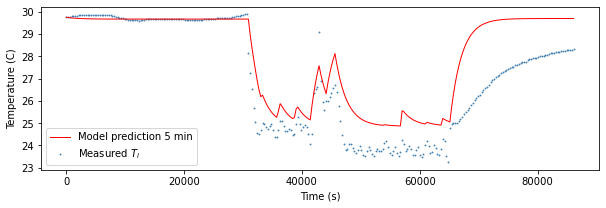

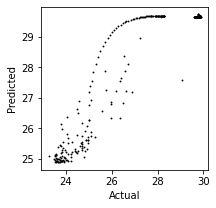

In [31]:
# Forecast graph
plt.figure(figsize=(10,3))
plt.scatter(pred_df.index, pred_output, color="steelblue", marker='.', label='Measured $T_i$', s=3)
plt.plot(pred_df.index, pred_simpleRC(pred_inputs, p_opt_2P[0], p_opt_2P[1], p_opt_2P[2], p_opt_2P[3], p_opt_2P[4], p_opt_2P[5]), 
         color="red",linewidth=1, label='Model prediction 5 min')

plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

# Scatter plots
plt.figure(figsize=(3,3))
plt.scatter(pred_output, pred_simpleRC(pred_inputs, p_opt_2P[0], p_opt_2P[1], p_opt_2P[2], p_opt_2P[3], p_opt_2P[4], p_opt_2P[5]), 
            color="black", marker='.', s=3)

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

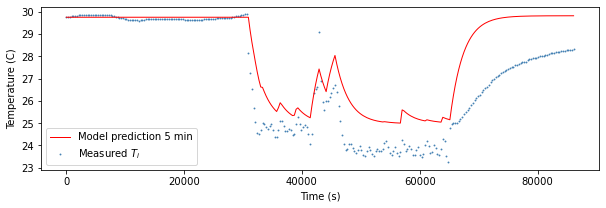

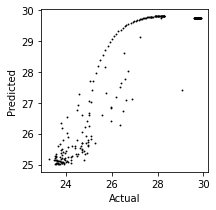

In [32]:
# Forecast graph
plt.figure(figsize=(10,3))
plt.scatter(pred_df.index, pred_output, color="steelblue", marker='.', label='Measured $T_i$', s=3)
plt.plot(pred_df.index, pred_simpleRC(pred_inputs, p_opt_3P[0], p_opt_3P[1], p_opt_3P[2], p_opt_3P[3], p_opt_3P[4], p_opt_3P[5]), 
         color="red",linewidth=1, label='Model prediction 5 min')

plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

# Scatter plots
plt.figure(figsize=(3,3))
plt.scatter(pred_output, pred_simpleRC(pred_inputs, p_opt_3P[0], p_opt_3P[1], p_opt_3P[2], p_opt_3P[3], p_opt_3P[4], p_opt_3P[5]), 
            color="black", marker='.', s=3)

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

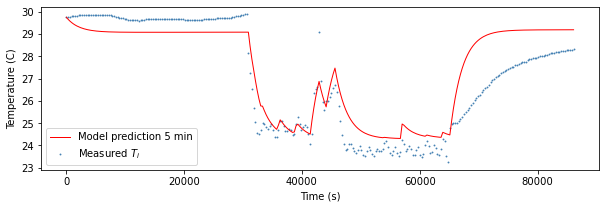

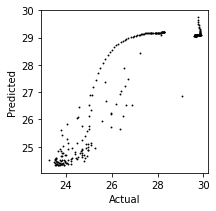

In [33]:
# Forecast graph
plt.figure(figsize=(10,3))
plt.scatter(pred_df.index, pred_output, color="steelblue", marker='.', label='Measured $T_i$', s=3)
plt.plot(pred_df.index, pred_simpleRC(pred_inputs, p_opt_4P[0], p_opt_4P[1], p_opt_4P[2], p_opt_4P[3], p_opt_4P[4], p_opt_4P[5]), 
         color="red",linewidth=1, label='Model prediction 5 min')

plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

# Scatter plots
plt.figure(figsize=(3,3))
plt.scatter(pred_output, pred_simpleRC(pred_inputs, p_opt_4P[0], p_opt_4P[1], p_opt_4P[2], p_opt_4P[3], p_opt_4P[4], p_opt_4P[5]), 
            color="black", marker='.', s=3)

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

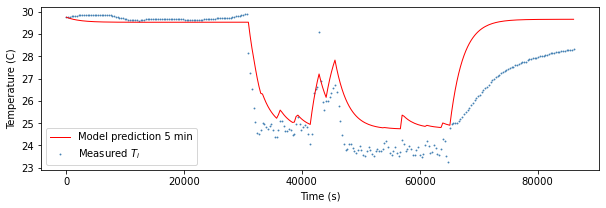

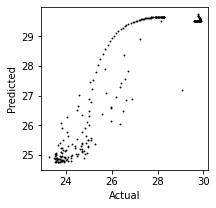

In [34]:
# Forecast graph
plt.figure(figsize=(10,3))
plt.scatter(pred_df.index, pred_output, color="steelblue", marker='.', label='Measured $T_i$', s=3)
plt.plot(pred_df.index, pred_simpleRC(pred_inputs, p_opt_5P[0], p_opt_5P[1], p_opt_5P[2], p_opt_5P[3], p_opt_5P[4], p_opt_5P[5]), 
         color="red",linewidth=1, label='Model prediction 5 min')

plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

# Scatter plots
plt.figure(figsize=(3,3))
plt.scatter(pred_output, pred_simpleRC(pred_inputs, p_opt_5P[0], p_opt_5P[1], p_opt_5P[2], p_opt_5P[3], p_opt_5P[4], p_opt_5P[5]), 
            color="black", marker='.', s=3)

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

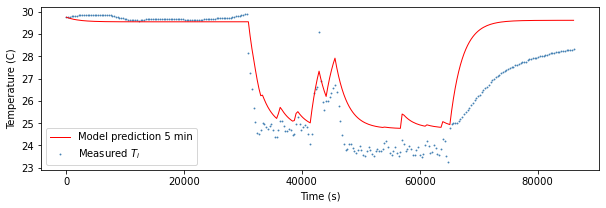

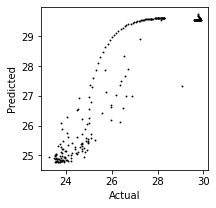

In [35]:
# Forecast graph
plt.figure(figsize=(10,3))
plt.scatter(pred_df.index, pred_output, color="steelblue", marker='.', label='Measured $T_i$', s=3)
plt.plot(pred_df.index, pred_outputs_avg, color="red",linewidth=1, label='Model prediction 5 min')

plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

# Scatter plots
plt.figure(figsize=(3,3))
plt.scatter(pred_output, pred_outputs_avg, color="black", marker='.', s=3)

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()